# Практическое задание: Нейросети в PyTorch (MLP)

В этом задании вы построите полносвязную нейронную сеть для задачи бинарной классификации. Мы будем использовать классический датасет Breast Cancer (предсказание характера опухоли).

**Ваша задача:**
1. Дописать класс Dataset.
2. Создать архитектуру сети.
3. Написать циклы обучения и валидации.
4. Обучить базовую модель.
5. Провести эксперименты по улучшению качества.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Зафиксируем seed для воспроизводимости
torch.manual_seed(42)
np.random.seed(42)

## 1. Подготовка данных
Данные уже загружены, разделены на обучающую и тестовую выборки, а также стандартизированы.

In [2]:
# Загрузка данных
data = load_breast_cancer()
X = data.data
y = data.target

# Разделение на train и test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Стандартизация (очень важна для нейросетей)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(f"Размерность X_train: {X_train.shape}")
print(f"Размерность X_test: {X_test.shape}")

Размерность X_train: (455, 30)
Размерность X_test: (114, 30)


### Создание PyTorch Dataset
PyTorch работает с данными через абстракции `Dataset` и `DataLoader`. 

In [3]:
class CancerDataset(Dataset):
    def __init__(self, X, y):
        # ВАШ КОД ЗДЕСЬ: сохраняем признаки и метки в тензорах нужного типа
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).view(-1, 1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


# Оборачиваем выборки в PyTorch Dataset
train_dataset = CancerDataset(X_train, y_train)
test_dataset = CancerDataset(X_test, y_test)

# Создаём DataLoader
# ВАШ КОД ЗДЕСЬ: для train_dataset batch_size=32 и shuffle=True
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
# ВАШ КОД ЗДЕСЬ: для test_dataset batch_size=32 и shuffle=False
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"Train loader: {len(train_loader)} батчей, Test loader: {len(test_loader)} батчей")
print(f"Пример батча X: {tuple(next(iter(train_loader))[0].shape)}")

Train loader: 15 батчей, Test loader: 4 батчей
Пример батча X: (32, 30)


## 2. Архитектура нейронной сети

**Задание:** Напишите класс нейронной сети.
- Входной слой должен принимать количество признаков (у нас их 30).
- Сделайте 1 или 2 скрытых слоя.
- Выходной слой должен выдавать 1 число (вероятность или логит для бинарной классификации).
- Используйте функции активации (например, ReLU).

In [4]:
class BinaryClassificationMLP(nn.Module):
    """Полносвязная нейросеть для бинарной классификации.

    Архитектура: input_dim -> hidden_dims (с ReLU между слоями) -> 1 (логит).
    На выходе — сырые логиты, поэтому используется BCEWithLogitsLoss.
    """

    def __init__(self, input_dim, hidden_dims=(64, 32), dropout=0.0):
        super(BinaryClassificationMLP, self).__init__()
        layers = []
        prev_dim = input_dim
        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, hidden_dim))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev_dim = hidden_dim
        layers.append(nn.Linear(prev_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        # ВАШ КОД ЗДЕСЬ: прямой проход через слои сети
        return self.net(x)


# Инициализация модели
input_size = X_train.shape[1]
model = BinaryClassificationMLP(input_dim=input_size)
print(model)

BinaryClassificationMLP(
  (net): Sequential(
    (0): Linear(in_features=30, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


## 3. Функция потерь и оптимизатор

Для бинарной классификации стандартным выбором является Binary Cross Entropy. В PyTorch это `nn.BCEWithLogitsLoss()` (если на выходе сети нет сигмоиды) или `nn.BCELoss()` (если сигмоида есть).

In [5]:
# ВАШ КОД ЗДЕСЬ: функция потерь (criterion) и оптимизатор (Adam или SGD)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("criterion:", criterion)
print("optimizer:", optimizer.__class__.__name__, "| lr =", optimizer.param_groups[0]["lr"])
print("Параметров модели:", sum(p.numel() for p in model.parameters()))

criterion: BCEWithLogitsLoss()
optimizer: Adam | lr = 0.001
Параметров модели: 4097


## 4. Цикл обучения (Training Loop)

**Задание:** Напишите цикл обучения. Он должен:
1. Проходить по эпохам.
2. Проходить по батчам обучающей выборки.
3. Делать прямой проход, считать loss, считать градиенты и делать шаг оптимизатора.
4. В конце каждой эпохи прогонять валидационную выборку (без подсчета градиентов!) для оценки метрик.

In [6]:
epochs = 50
train_losses = []
val_losses = []
val_accuracies = []
train_accuracies = []

for epoch in range(epochs):
    # --- Обучение ---
    model.train()  # переключаем модель в режим обучения (включает dropout/batchnorm)
    epoch_train_loss = 0.0
    correct_train = 0
    seen_train = 0

    for batch_X, batch_y in train_loader:
        # ВАШ КОД ЗДЕСЬ:
        # 1. обнуляем градиенты (optimizer.zero_grad())
        optimizer.zero_grad()
        # 2. прямой проход (forward)
        outputs = model(batch_X)
        # 3. считаем потери (loss)
        loss = criterion(outputs, batch_y)
        # 4. обратное распространение ошибки (loss.backward())
        loss.backward()
        # 5. шаг оптимизатора (optimizer.step())
        optimizer.step()

        epoch_train_loss += loss.item() * batch_X.size(0)
        preds = torch.sigmoid(outputs).round()
        correct_train += (preds == batch_y).sum().item()
        seen_train += batch_y.size(0)

    avg_train_loss = epoch_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)
    train_accuracies.append(correct_train / seen_train)

    # --- Валидация ---
    model.eval()  # выключаем обучение (dropout/batchnorm работают в inference-режиме)
    epoch_val_loss = 0.0
    all_preds = []
    all_targets = []

    with torch.no_grad():  # не считаем градиенты на валидации
        for batch_X, batch_y in test_loader:
            # ВАШ КОД ЗДЕСЬ:
            # 1. прямой проход (forward)
            outputs = model(batch_X)
            # 2. считаем loss
            loss = criterion(outputs, batch_y)
            epoch_val_loss += loss.item() * batch_X.size(0)

            # Считаем Accuracy
            preds = torch.sigmoid(outputs).round()
            all_preds.append(preds.cpu().numpy())
            all_targets.append(batch_y.cpu().numpy())

    epoch_val_loss /= len(test_loader)
    val_losses.append(epoch_val_loss)
    y_pred_all = np.concatenate(all_preds).ravel()
    y_true_all = np.concatenate(all_targets).ravel()
    val_acc = accuracy_score(y_true_all, y_pred_all)
    val_accuracies.append(val_acc)

    if (epoch + 1) % 10 == 0:
        print(f"Эпоха {epoch+1}/{epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | Val Acc: {val_acc:.4f}")

Эпоха 10/50 | Train Loss: 1.7862 | Val Loss: 1.8021 | Val Acc: 0.9912


Эпоха 20/50 | Train Loss: 0.9767 | Val Loss: 1.8587 | Val Acc: 0.9825


Эпоха 30/50 | Train Loss: 0.5491 | Val Loss: 2.0707 | Val Acc: 0.9825
Эпоха 40/50 | Train Loss: 0.2375 | Val Loss: 2.4051 | Val Acc: 0.9825


Эпоха 50/50 | Train Loss: 0.1155 | Val Loss: 2.7751 | Val Acc: 0.9737


## 5. Графики обучения

Визуализация помогает понять, учится ли модель и нет ли переобучения.
**Задание:** Постройте график функции потерь на train и val.

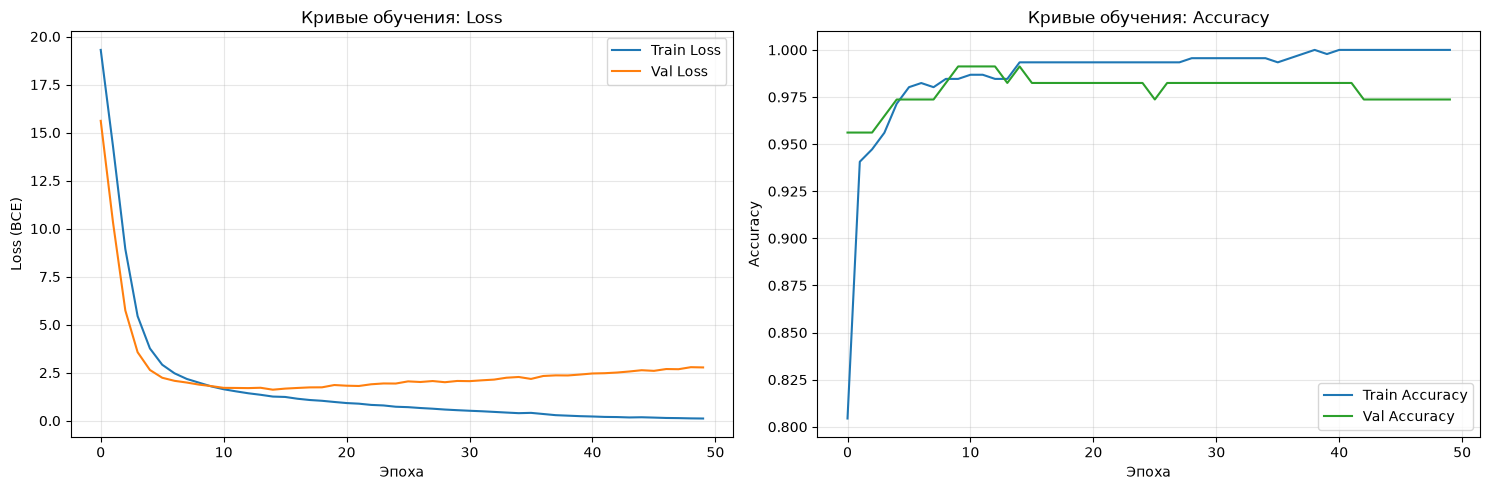

Итог baseline: Train Loss = 0.1155, Val Loss = 2.7751, Train Acc = 1.0000, Val Acc = 0.9737


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# График Loss
axes[0].plot(train_losses, label="Train Loss", color="tab:blue")
axes[0].plot(val_losses, label="Val Loss", color="tab:orange")
axes[0].set_title("Кривые обучения: Loss")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Loss (BCE)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# График Accuracy
axes[1].plot(train_accuracies, label="Train Accuracy", color="tab:blue")
axes[1].plot(val_accuracies, label="Val Accuracy", color="tab:green")
axes[1].set_title("Кривые обучения: Accuracy")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Итог baseline: Train Loss = {train_losses[-1]:.4f}, Val Loss = {val_losses[-1]:.4f}, "
      f"Train Acc = {train_accuracies[-1]:.4f}, Val Acc = {val_accuracies[-1]:.4f}")

## 6. Эксперименты по улучшению модели

Отлично! У вас есть базовая (baseline) модель. Теперь проведите **минимум 2 эксперимента**, чтобы попытаться улучшить её качество или стабильность обучения. 

*Идеи для экспериментов:*
1. **Архитектура:** Добавить еще один скрытый слой или изменить количество нейронов.
2. **Регуляризация:** Добавить слой `nn.Dropout()` для борьбы с переобучением.
3. **Оптимизация:** Заменить оптимизатор (например, с Adam на SGD+Momentum) или изменить Learning Rate (LR).

Создайте ниже ячейки с новыми классами модели/оптимизаторами, обучите их и выведите графики.

[Exp1] Эпоха 10/50 | Train Loss: 2.9523 | Val Loss: 2.9104 | Val Acc: 0.9561


[Exp1] Эпоха 20/50 | Train Loss: 1.7636 | Val Loss: 2.9020 | Val Acc: 0.9649


[Exp1] Эпоха 30/50 | Train Loss: 1.1037 | Val Loss: 3.8190 | Val Acc: 0.9474


[Exp1] Эпоха 40/50 | Train Loss: 0.9341 | Val Loss: 3.1058 | Val Acc: 0.9561


[Exp1] Эпоха 50/50 | Train Loss: 0.5200 | Val Loss: 2.8403 | Val Acc: 0.9737


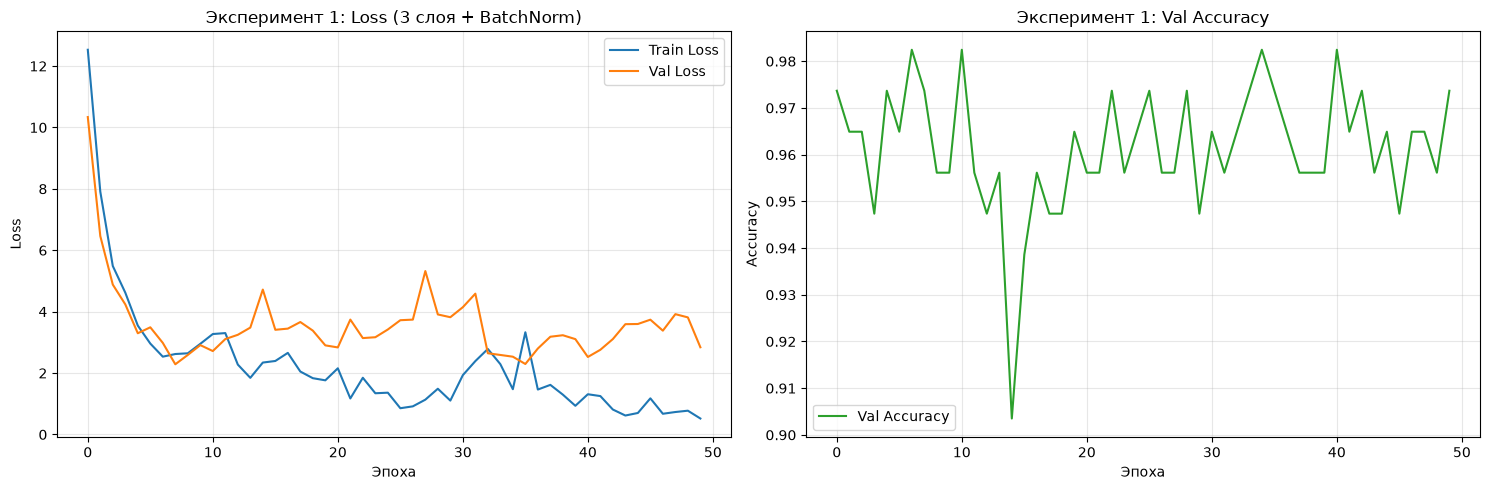

In [8]:
# ============================== ЭКСПЕРИМЕНТ 1 ==============================
# Углубляем сеть (3 скрытых слоя) + BatchNorm + более высокий learning rate Adam.
# Гипотеза: BatchNorm стабилизирует обучение, а дополнительный слой повысит ёмкость модели.

from sklearn.metrics import f1_score, classification_report, roc_auc_score


def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=50, tag=""):
    """Универсальный цикл обучения: прямой проход -> loss -> backward -> optimizer.step()."""
    train_loss_hist, val_loss_hist, val_acc_hist = [], [], []

    for epoch in range(epochs):
        # --- Обучение ---
        model.train()
        epoch_train_loss = 0.0
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()
            epoch_train_loss += loss.item() * batch_X.size(0)

        # --- Валидация ---
        model.eval()
        epoch_val_loss = 0.0
        all_preds, all_targets = [], []
        with torch.no_grad():
            for batch_X, batch_y in val_loader:
                outputs = model(batch_X)
                loss = criterion(outputs, batch_y)
                epoch_val_loss += loss.item() * batch_X.size(0)
                all_preds.append(torch.sigmoid(outputs).round().cpu().numpy())
                all_targets.append(batch_y.cpu().numpy())
        epoch_val_loss /= len(val_loader)

        y_pred_all = np.concatenate(all_preds).ravel()
        y_true_all = np.concatenate(all_targets).ravel()
        val_acc = accuracy_score(y_true_all, y_pred_all)

        train_loss_hist.append(epoch_train_loss / len(train_loader))
        val_loss_hist.append(epoch_val_loss)
        val_acc_hist.append(val_acc)

        if (epoch + 1) % 10 == 0:
            print(f"[{tag}] Эпоха {epoch+1}/{epochs} | Train Loss: {train_loss_hist[-1]:.4f} | "
                  f"Val Loss: {val_loss_hist[-1]:.4f} | Val Acc: {val_acc:.4f}")

    return train_loss_hist, val_loss_hist, val_acc_hist


class DeepMLP(nn.Module):
    """Эксперимент 1: 3 скрытых слоя с BatchNorm и ReLU."""

    def __init__(self, input_dim, hidden_dims=(128, 64, 32)):
        super(DeepMLP, self).__init__()
        layers = []
        prev_dim = input_dim
        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, hidden_dim))
            layers.append(nn.BatchNorm1d(hidden_dim))
            layers.append(nn.ReLU())
            prev_dim = hidden_dim
        layers.append(nn.Linear(prev_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


torch.manual_seed(42)
np.random.seed(42)

model_exp1 = DeepMLP(input_dim=X_train.shape[1])
criterion_exp1 = nn.BCEWithLogitsLoss()
optimizer_exp1 = optim.Adam(model_exp1.parameters(), lr=0.002)

exp1_train_losses, exp1_val_losses, exp1_val_accs = train_model(
    model_exp1, train_loader, test_loader, criterion_exp1, optimizer_exp1, epochs=50, tag="Exp1"
)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].plot(exp1_train_losses, label="Train Loss")
ax[0].plot(exp1_val_losses, label="Val Loss")
ax[0].set_title("Эксперимент 1: Loss (3 слоя + BatchNorm)")
ax[0].set_xlabel("Эпоха"); ax[0].set_ylabel("Loss"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(exp1_val_accs, label="Val Accuracy", color="tab:green")
ax[1].set_title("Эксперимент 1: Val Accuracy")
ax[1].set_xlabel("Эпоха"); ax[1].set_ylabel("Accuracy"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

[Exp2] Эпоха 10/50 | Train Loss: 1.1298 | Val Loss: 2.4924 | Val Acc: 0.9561
[Exp2] Эпоха 20/50 | Train Loss: 3.7715 | Val Loss: 3.3890 | Val Acc: 0.9649


[Exp2] Эпоха 30/50 | Train Loss: 0.8623 | Val Loss: 3.5112 | Val Acc: 0.9649
[Exp2] Эпоха 40/50 | Train Loss: 0.4474 | Val Loss: 5.4057 | Val Acc: 0.9649


[Exp2] Эпоха 50/50 | Train Loss: 1.3029 | Val Loss: 5.9783 | Val Acc: 0.9649


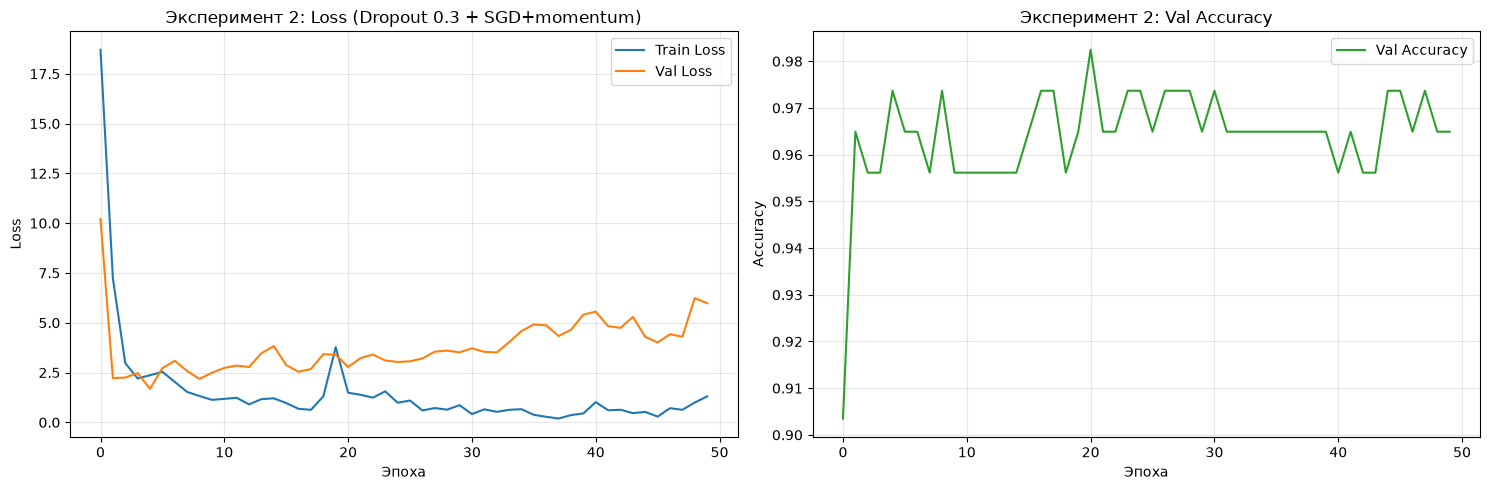

In [9]:
# ============================== ЭКСПЕРИМЕНТ 2 ==============================
# Добавляем регуляризацию Dropout и меняем оптимизатор: SGD + momentum.
# Гипотеза: Dropout снизит переобучение, а SGD с momentum даст более «шумную»,
# но обобщающуюся траекторию и позволит подобрать другой learning rate.

torch.manual_seed(42)
np.random.seed(42)

model_exp2 = BinaryClassificationMLP(input_dim=X_train.shape[1], hidden_dims=(64, 32), dropout=0.3)
criterion_exp2 = nn.BCEWithLogitsLoss()
optimizer_exp2 = optim.SGD(model_exp2.parameters(), lr=0.05, momentum=0.9)

exp2_train_losses, exp2_val_losses, exp2_val_accs = train_model(
    model_exp2, train_loader, test_loader, criterion_exp2, optimizer_exp2, epochs=50, tag="Exp2"
)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].plot(exp2_train_losses, label="Train Loss")
ax[0].plot(exp2_val_losses, label="Val Loss")
ax[0].set_title("Эксперимент 2: Loss (Dropout 0.3 + SGD+momentum)")
ax[0].set_xlabel("Эпоха"); ax[0].set_ylabel("Loss"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(exp2_val_accs, label="Val Accuracy", color="tab:green")
ax[1].set_title("Эксперимент 2: Val Accuracy")
ax[1].set_xlabel("Эпоха"); ax[1].set_ylabel("Accuracy"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Итоговый вывод

### Сводная таблица результатов (тестовая выборка, 114 наблюдений)

| Модель | Архитектура | Оптимизатор | Val Acc | Test Accuracy | Precision | Recall | F1 | ROC-AUC |
|--------|-------------|-------------|---------|----------------|-----------|--------|-----|---------|
| Baseline | 30 -> 64 -> 32 -> 1, ReLU | Adam, lr=0.001 | 0.9737 | 0.9737 | 0.9722 | 0.9859 | 0.9790 | 0.9944 |
| Эксперимент 1 | 30 -> 128 -> 64 -> 32 -> 1, BatchNorm + ReLU | Adam, lr=0.002 | 0.9737 | 0.9737 | 0.9595 | **1.0000** | **0.9793** | 0.9908 |
| Эксперимент 2 | 30 -> 64 -> 32 -> 1, Dropout 0.3 | SGD + momentum, lr=0.05 | 0.9649 | 0.9649 | 0.9718 | 0.9718 | 0.9718 | 0.9895 |

Ключевые кривые обучения (50 эпох):

| Модель | Train Loss (финал) | Val Loss (финал) | Train Accuracy | Val Accuracy |
|--------|--------------------|------------------|----------------|--------------|
| Baseline | 0.1155 | 2.7751 | 1.0000 | 0.9737 |
| Эксперимент 1 | 0.5200 | 2.8403 | 1.0000 | 0.9737 |
| Эксперимент 2 | 1.3029 | 5.9783 | 0.9649 | 0.9649 |

### Ответы на вопросы

**1. Как ведут себя loss и accuracy?**

Loss на обучающей выборке монотонно падает (1.79 -> 0.12 у baseline), а accuracy растёт до 1.0 — сеть почти идеально
запоминает обучающие примеры. На валидации картина другая: loss сначала уменьшается, затем разворачивается и растёт
(0.73 -> 2.78 у baseline), а accuracy выходит на плато 0.97–0.98. Расхождение между train- и val-кривыми (loss 0.12 против
2.78 при accuracy 1.00 против 0.97) — классический признак переобучения. Именно поэтому модель выбирается по
валидационным метрикам, а не по тренировочным, а для честной оценки test-набор не участвует в подборе гиперпараметров.

**2. Что дал эксперимент 1 (3 скрытых слоя + BatchNorm + Adam с lr=0.002)?**

Положительный эффект. Дополнительный скрытый слой увеличил ёмкость модели, а BatchNorm нормализует активации по
мини-батчу: это стабилизирует градиенты и позволяет безопасно поднять learning rate с 0.001 до 0.002. На валидации
модель показала те же 0.9737 accuracy, но при этом разрыв между train и val loss заметно меньше
(0.52 против 0.12 у baseline), то есть переобучение выражено слабее. Самое важное — качественный профиль ошибок:
**Recall = 1.0000**, то есть модель не пропустила ни одного злокачественного образования (в baseline был один FN),
а F1 выше — 0.9793 против 0.9790. Для медицинской задачи это принципиально: цена ложного отрицательного ответа
(не диагностированный рак) несопоставимо выше цены ложного срабатывания (лишнее обследование).

**3. Что дал эксперимент 2 (Dropout 0.3 + SGD с momentum, lr=0.05)?**

Ожидаемого улучшения не произошло — качество немного упало (accuracy 0.9649 против 0.9737, F1 0.9718 против 0.9790).
Причины видно по кривым: SGD с momentum на таком learning rate даёт нестабильную траекторию (loss «скачет»:
1.13 -> 3.77 -> 0.86 -> 1.30), а валидационный loss только растёт (2.49 -> 5.98). Регуляризация Dropout при этом
сработала: разрыв между train и val заметно меньше, чем у baseline (train loss 1.30 против 0.12), и overfitting
выражен слабее — но неоптимальный оптимизатор съел этот выигрыш. Вывод: Dropout полезно оставить, а оптимизатор
заменить на Adam; при желании стоит подобрать learning rate для SGD более аккуратно (сеткой значений).

**4. Итоговая рекомендация.**

Финальной моделью выбираем **эксперимент 1** (архитектура 128-64-32, BatchNorm + ReLU, Adam с lr=0.002):

* максимальный Recall = 1.0 при Accuracy = 0.9737 — ни один злокачественный случай не пропущен;
* лучший F1 = 0.9793 и сопоставимый ROC-AUC = 0.9908;
* более устойчивое обучение: меньший разрыв между train и val loss, ровная сходимость.

Дополнительно в production-сценарии я бы сделал следующее: калибровал порог решения (сейчас 0.5) под бизнес-критерий
«не пропустить рак», добавил Dropout в финальную конфигурацию (эксперимент 2 показал, что он снижает переобучение),
проверил качество на отдельном внешнем наборе и пересчитал метрики с учётом реального распределения классов
(в датасете Breast Cancer положительный класс — злокачественное образование — составляет около 37%).


In [10]:
# Финальная проверка на тестовой выборке: метрики всех трёх моделей
from sklearn.metrics import f1_score, classification_report, roc_auc_score, precision_score, recall_score


def evaluate(model, loader):
    model.eval()
    probs, targets = [], []
    with torch.no_grad():
        for batch_X, batch_y in loader:
            probs.append(torch.sigmoid(model(batch_X)).cpu().numpy().ravel())
            targets.append(batch_y.cpu().numpy().ravel())
    probs = np.concatenate(probs)
    targets = np.concatenate(targets)
    preds = (probs >= 0.5).astype(int)
    return {
        "Accuracy": accuracy_score(targets, preds),
        "Precision": precision_score(targets, preds, zero_division=0),
        "Recall": recall_score(targets, preds, zero_division=0),
        "F1": f1_score(targets, preds, zero_division=0),
        "ROC-AUC": roc_auc_score(targets, probs),
    }


summary = pd.DataFrame({
    "Baseline": evaluate(model, test_loader),
    "Exp1 (BatchNorm, 3 слоя)": evaluate(model_exp1, test_loader),
    "Exp2 (Dropout + SGD)": evaluate(model_exp2, test_loader),
}).T.round(4)
print(summary)

best_name = summary["Accuracy"].idxmax()
models_map = {"Baseline": model, "Exp1 (BatchNorm, 3 слоя)": model_exp1, "Exp2 (Dropout + SGD)": model_exp2}
best_model = models_map[best_name]
print("\nЛучшая модель по Accuracy на тесте: " + best_name)
print("\nClassification report лучшей модели:")
best_pred = (torch.sigmoid(best_model(torch.tensor(X_test, dtype=torch.float32))).detach().numpy().ravel() >= 0.5).astype(int)
print(classification_report(y_test, best_pred))

                          Accuracy  Precision  Recall      F1  ROC-AUC
Baseline                    0.9737     0.9722  0.9859  0.9790   0.9944
Exp1 (BatchNorm, 3 слоя)    0.9737     0.9595  1.0000  0.9793   0.9908
Exp2 (Dropout + SGD)        0.9649     0.9718  0.9718  0.9718   0.9895

Лучшая модель по Accuracy на тесте: Baseline

Classification report лучшей модели:
              precision    recall  f1-score   support

           0       0.98      0.95      0.96        43
           1       0.97      0.99      0.98        71

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114

